# Pandas e Pré-processamento de Dados para Machine Learning
### Estudo de caso: Titanic 🚢

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


RANDOM_STATE = 42
print("pandas", pd.__version__)

pandas 3.0.5


### Carregando os dados

Usamos a versão do Kaggle (`train.csv`, 891 passageiros com o rótulo `Survived`)

| Coluna | Significado |
|---|---|
| `PassengerId` | identificador |
| `Survived` | **alvo** (0 = não, 1 = sim) |
| `Pclass` | classe do bilhete (1 = 1ª, 2 = 2ª, 3 = 3ª) |
| `Name`, `Sex`, `Age` | nome, sexo, idade |
| `SibSp` | nº de irmãos/cônjuges a bordo |
| `Parch` | nº de pais/filhos a bordo |
| `Ticket`, `Fare` | bilhete e tarifa paga |
| `Cabin` | cabine |
| `Embarked` | porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton) |

In [ ]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_raw = pd.read_csv(URL)

df = df_raw.copy()   # sempre preserve uma cópia do dado original!
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


## 2. Primeiro contato com o DataFrame

Antes de qualquer modelo: **quantas linhas? quantas colunas? quais tipos? onde faltam dados?**

In [ ]:
print("Formato (linhas, colunas):", df.shape)
df.info()

Formato (linhas, colunas): (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [ ]:
# Estatísticas descritivas das colunas numéricas
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000,891.000,891.000,714.000,891.000,891.000,891.000
mean,446.000,0.384,2.309,29.699,0.523,0.382,32.204
std,257.354,0.487,0.836,14.526,1.103,0.806,49.693
min,1.000,0.000,1.000,0.420,0.000,0.000,0.000
25%,223.500,0.000,2.000,20.125,0.000,0.000,7.910
50%,446.000,0.000,3.000,28.000,0.000,0.000,14.454
75%,668.500,1.000,3.000,38.000,1.000,0.000,31.000
max,891.000,1.000,3.000,80.000,8.000,6.000,512.329


## 3. Agregações: `groupby`, `agg`

Muito bom para **gerar hipóteses** antes de modelar.

In [ ]:
# Taxa de sobrevivência geral (média de uma variável 0/1 = proporção de 1s)
print(f"Taxa de sobrevivência: {df['Survived'].mean():.1%}")

# Por sexo
df.groupby("Sex")["Survived"].mean()

Taxa de sobrevivência: 38.4%


Sex
female   0.742
male     0.189
Name: Survived, dtype: float64

In [ ]:
# Várias estatísticas de uma vez
df.groupby("Pclass").agg(
    n_passageiros=("PassengerId", "count"),
    taxa_sobrevivencia=("Survived", "mean"),
    idade_media=("Age", "mean"),
    tarifa_mediana=("Fare", "median"),
)

,n_passageiros,taxa_sobrevivencia,idade_media,tarifa_mediana
Pclass,,,,
1,216,0.630,38.233,60.287
2,184,0.473,29.878,14.250
3,491,0.242,25.141,8.050


In [ ]:
# Duas dimensões: sexo x classe
df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [ ]:
# crosstab: tabela de contingência (normalize="index" -> proporção por linha)
pd.crosstab(df["Embarked"], df["Survived"], normalize="index")

Survived,0,1
Embarked,,
C,0.446,0.554
Q,0.610,0.390
S,0.663,0.337


## 4. Dados faltantes

Três decisões possíveis para cada coluna:
1. **Remover a coluna** (se falta quase tudo e não há como recuperar).
2. **Remover as linhas** (se faltam pouquíssimas e o dataset é grande).
3. **Imputar** (preencher com um valor razoável) — e, às vezes, **criar uma flag** indicando que estava faltando.

In [ ]:
faltantes = pd.DataFrame({
    "n_faltantes": df.isna().sum(),
    "pct_faltantes": df.isna().mean() * 100,
}).query("n_faltantes > 0").sort_values("pct_faltantes", ascending=False)
faltantes

,n_faltantes,pct_faltantes
Cabin,687,77.104
Age,177,19.865
Embarked,2,0.224


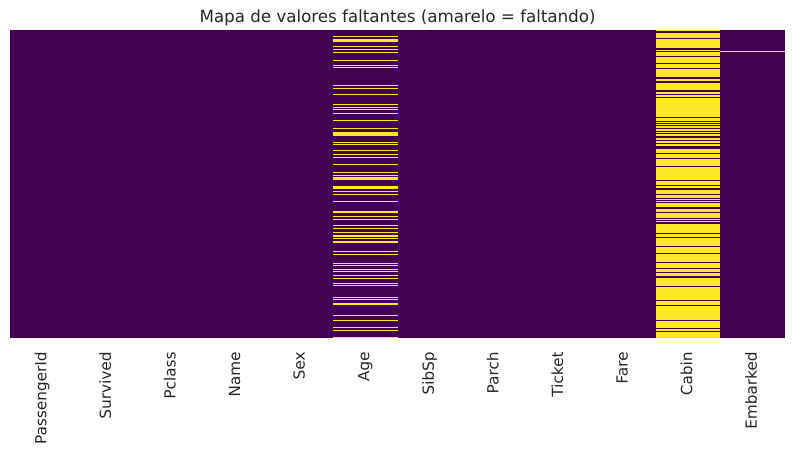

In [ ]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de valores faltantes (amarelo = faltando)")
plt.show()

### 4.1 `Cabin` (~77% faltando)
Faltam valores demais para imputar a cabine. Mas **o fato de faltar é informativo**: passageiros de 1ª classe tinham
cabine registrada com muito mais frequência. Vamos transformar isso em uma variável binária (uma *flag*).

In [ ]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df.groupby("HasCabin")["Survived"].mean()

HasCabin
0   0.300
1   0.667
Name: Survived, dtype: float64

### 4.2 `Embarked` (2 valores faltando)
Poucos valores → imputar com a **moda** (valor mais frequente) é razoável.

In [ ]:
moda_embarked = df["Embarked"].mode()[0]
print("Moda:", moda_embarked)

# Atenção: evite df["col"].fillna(..., inplace=True) — no pandas moderno isso NÃO altera o df.
df["Embarked"] = df["Embarked"].fillna(moda_embarked)
df["Embarked"].isna().sum()

Moda: S


np.int64(0)

### 4.3 `Age` (~20% faltando)
Vamos imputar com a **mediana** da idade. Por que a mediana e não a média? A mediana é menos sensível a valores extremos.

In [ ]:
mediana_idade = df["Age"].median()
print("Mediana da idade:", mediana_idade)

df["Age"] = df["Age"].fillna(mediana_idade)
print("Faltantes restantes em Age:", df["Age"].isna().sum())

Mediana da idade: 28.0
Faltantes restantes em Age: 0


## 5. Feature engineering

Criar variáveis que tornam padrões **mais fáceis de o modelo aprender**.

In [ ]:
# Tamanho da família = irmãos/cônjuge + pais/filhos + a própria pessoa
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df.groupby("FamilySize")["Survived"].agg(["mean", "count"])

,mean,count
FamilySize,,
1,0.304,537
2,0.553,161
3,0.578,102
4,0.724,29
5,0.200,15
6,0.136,22
7,0.333,12
8,0.000,6
11,0.000,7


In [ ]:
# Deck = primeira letra da cabine ("U" = desconhecido)
df["Deck"] = df["Cabin"].str[0].fillna("U")
df.groupby("Deck")["Survived"].agg(["mean", "count"])

,mean,count
Deck,,
A,0.467,15
B,0.745,47
C,0.593,59
D,0.758,33
E,0.750,32
F,0.615,13
G,0.500,4
T,0.000,1
U,0.300,687


In [ ]:
# Descartando colunas que já foram aproveitadas ou que são identificadores
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin,FamilySize,IsAlone,Deck
0,0,3,male,22.000,1,0,7.250,S,0,2,0,U
1,1,1,female,38.000,1,0,71.283,C,1,2,0,C
2,1,3,female,26.000,0,0,7.925,S,0,1,1,U
3,1,1,female,35.000,1,0,53.100,S,1,2,0,C
4,0,3,male,35.000,0,0,8.050,S,0,1,1,U


## 6. Encoding de variáveis categóricas

Modelos trabalham com números. A forma de converter depende do **tipo** de categoria:

| Tipo | Exemplo | Há ordem? | Técnica |
|---|---|---|---|
| **Binária** | `Sex` (male/female) | — | mapear para 0/1 |
| **Ordinal** | `Pclass` (1ª < 2ª < 3ª) | ✅ | **Ordinal encoding** (inteiros respeitando a ordem) |
| **Nominal** | `Embarked`, `Deck` | ❌ | **One-hot encoding** (uma coluna 0/1 por categoria) |

> ❗ **Erro clássico:** codificar `Embarked` como S=0, C=1, Q=2. O modelo vai entender que Q > C > S e que
> "a distância de S a Q é o dobro da de S a C" — uma relação que **não existe**.

In [ ]:
categoricas = df.select_dtypes(exclude="number").columns.tolist()
print("Colunas não numéricas:", categoricas)

Colunas não numéricas: ['Sex', 'Embarked', 'Deck']


### 6.1 Variável binária → `map`
Só duas categorias: basta trocar cada uma por 0 ou 1.

In [ ]:
df_enc = df.copy()
df_enc["Sex"] = df_enc["Sex"].map({"male": 0, "female": 1})
df_enc["Sex"].value_counts()

Sex
0    577
1    314
Name: count, dtype: int64

### 6.2 Variável ordinal → inteiros respeitando a ordem
As categorias têm uma ordem natural, então usamos números que **preservam essa ordem**.
`Pclass` já é ordinal e já está em inteiros (1 < 2 < 3), então podemos mantê-la como está.

### 6.3 Variáveis nominais → one-hot encoding
Não há ordem entre as categorias, então criamos **uma coluna 0/1 para cada categoria**.
Cada passageiro tem 1 na coluna do seu porto e 0 nas demais.

In [ ]:
pd.get_dummies(df[["Embarked"]], dtype=int).head()

,Embarked_C,Embarked_Q,Embarked_S
0,0,0,1
1,1,0,0
2,0,0,1
3,0,0,1
4,0,0,1


In [ ]:
df_enc = pd.get_dummies(df_enc, columns=["Embarked", "Deck"], dtype=int)
print("Formato após one-hot:", df_enc.shape)
df_enc.head()

Formato após one-hot: (891, 22)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
0,0,3,0,22.000,1,0,7.250,0,2,0,0,0,1,0,0,0,0,0,0,0,0,1
1,1,1,1,38.000,1,0,71.283,1,2,0,1,0,0,0,0,1,0,0,0,0,0,0
2,1,3,1,26.000,0,0,7.925,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1
3,1,1,1,35.000,1,0,53.100,1,2,0,0,0,1,0,0,1,0,0,0,0,0,0
4,0,3,0,35.000,0,0,8.050,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1


## 7. Escalonamento de variáveis numéricas

`Age` vai de 0 a 80, `Fare` de 0 a 512, `IsAlone` de 0 a 1. Para muitos modelos (KNN, SVM, regressão logística,
redes neurais), essas escalas diferentes distorcem o aprendizado. Modelos de **árvore** (Decision Tree, Random Forest)
não precisam de escalonamento.

Vamos usar o `StandardScaler`, que deixa cada coluna com **média 0 e desvio padrão 1**:

$$z = \frac{x - \mu}{\sigma}$$

## 8. Finalmente: o modelo

Separamos treino e teste e escalonamos as colunas numéricas. O `StandardScaler` aprende média e desvio
**no treino** (`fit_transform`) e aplica os mesmos valores no teste (`transform`).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_enc.drop(columns="Survived")
y = df_enc["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

num_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
X_train.head()

Treino: (712, 21) | Teste: (179, 21)


,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
692,3,0,-0.112,-0.465,-0.466,0.514,0,-0.556,1,0,0,1,0,0,0,0,0,0,0,0,1
481,2,0,-0.112,-0.465,-0.466,-0.663,0,-0.556,1,0,0,1,0,0,0,0,0,0,0,0,1
527,1,0,-0.112,-0.465,-0.466,3.955,1,-0.556,1,0,0,1,0,0,1,0,0,0,0,0,0
855,3,1,-0.880,-0.465,0.728,-0.468,0,0.073,0,0,0,1,0,0,0,0,0,0,0,0,1
801,2,1,0.118,0.478,0.728,-0.116,0,0.703,0,0,0,1,0,0,0,0,0,0,0,0,1


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

modelos = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE),
}

resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    resultados[nome] = accuracy_score(y_test, modelo.predict(X_test))

pd.Series(resultados, name="acurácia (teste)").to_frame()

,acurácia (teste)
Baseline (classe majoritária),0.615
Regressão Logística,0.816
Random Forest,0.788


> Sempre compare com um **baseline**. Se seu modelo não supera "chutar sempre que morreu", algo está errado.

                precision    recall  f1-score   support

Não sobreviveu       0.82      0.89      0.86       110
    Sobreviveu       0.80      0.70      0.74        69

      accuracy                           0.82       179
     macro avg       0.81      0.79      0.80       179
  weighted avg       0.81      0.82      0.81       179



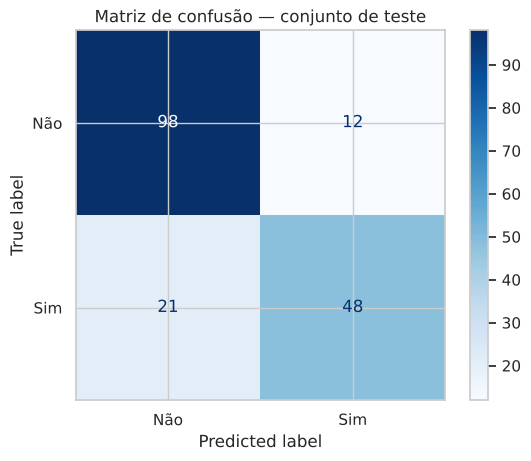

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

modelo_final = modelos["Regressão Logística"]
y_pred = modelo_final.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Não sobreviveu", "Sobreviveu"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Não", "Sim"], cmap="Blues")
plt.title("Matriz de confusão — conjunto de teste")
plt.show()

## 9. Exercício: Spaceship Titanic 🚀

Reproduza este notebook com o dataset **Spaceship Titanic** do Kaggle:
https://www.kaggle.com/competitions/spaceship-titanic/data (use o arquivo `train.csv`).

O alvo é `Transported` (se o passageiro foi transportado para outra dimensão). Siga as mesmas etapas da aula:

1. **Primeiro contato:** `shape`, `info()`, `describe()`.
2. **Agregações:** taxa de `Transported` por `HomePlanet`, por `CryoSleep` e por `Destination`.
3. **Dados faltantes:** quanto falta em cada coluna? Impute as numéricas com a mediana e as categóricas com a moda.
4. **Feature engineering:** a coluna `Cabin` tem o formato `deck/num/side` — separe em `Deck` e `Side`. Crie também o gasto total somando `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa` e `VRDeck`.
5. **Encoding:** classifique cada coluna categórica como binária, ordinal ou nominal e aplique o encoding adequado.
6. **Escalonamento:** aplique o `StandardScaler` nas colunas numéricas.
7. **Modelo:** treine o baseline, a regressão logística e a random forest. Qual foi a melhor acurácia?